# Noise Simulation with Qiskit Aer

**Course**: Quantum Computing Laboratory  
**Version**: 2.2 (Qiskit 2.2 Compatible)  
**Last Updated**: December 2025

---

## Contents

1. [Introduction to Quantum Noise](#intro)
2. [Types of Quantum Errors](#error_types)
3. [Building a Noise Model](#noise_model)
4. [Depolarizing Errors](#depolarizing)
5. [Thermal Relaxation (T1/T2)](#thermal)
6. [Measurement (Readout) Errors](#readout)
7. [Complete Noise Model](#complete)
8. [Noise Model from a Real Backend](#from_backend)
9. [Case Study: Grover's Algorithm](#grover)
10. [Exercises](#exercises)
11. [🔬 In-depth analysis](#indepth)

> Backend: this is the **IBM / Aer** edition — the `../IQM` folder has the IQM Garnet/Emerald edition.


<a id='intro'></a>
## 1. Introduction to Quantum Noise

### Why does noise matter?

Real quantum computers are affected by **noise**, which degrades the quality of the computation. The main sources are:

| Source | Description | Time scale |
|-------|-------------|------------------|
| **Decoherence** | Loss of quantum information | T1 ~ 100 us, T2 ~ 80 us |
| **Gate errors** | Imperfect operations | ~0.1% (1q), ~1% (2q) |
| **Measurement errors** | Wrong readout of the state | ~1-5% |
| **Crosstalk** | Interference between qubits | Depends on the topology |

### Goal of the notebook

Learn to:
1. Model different types of noise
2. Build custom noise models
3. Simulate circuits with realistic noise
4. Analyse the impact of noise on performance

In [1]:
# Imports
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister     # circuit builder (+ explicit registers, not used below)
from qiskit_aer import AerSimulator                                        # local simulator; AerSimulator(noise_model=...) makes it noisy
from qiskit_aer.primitives import SamplerV2                                # Aer's Sampler primitive: .run([circuits], shots) -> counts per classical register
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager   # transpiler: rewrite a circuit in a backend's gate set / connectivity
from qiskit.visualization import plot_histogram                            # bar chart of counts

# Noise modeling imports
from qiskit_aer.noise import (          # everything that describes noise lives in qiskit_aer.noise
    NoiseModel,                         # container: which error acts after which gate, on which qubits (+ readout errors)
    QuantumError,                       # a generic error channel (Kraus operators or (circuit, probability) pairs)
    ReadoutError,                       # classical confusion matrix applied to the measured bit
    depolarizing_error,                 # rho -> (1-p) rho + p I/d
    pauli_error,                        # a random Pauli with given probabilities, e.g. [('X', 0.1), ('I', 0.9)]
    thermal_relaxation_error,           # T1/T2 decay during a gate of given duration
    phase_damping_error,                # pure dephasing (T2 only)
    amplitude_damping_error             # energy relaxation |1> -> |0> (T1 only)
)

import numpy as np                      # arrays, exp, logspace
import matplotlib.pyplot as plt         # plots
from typing import Dict, List, Tuple    # type hints: List[float], Dict[str, int], Tuple[dict, dict] document what a function takes/returns (not enforced at run time)
from IPython.display import display                      # show a figure (e.g. a circuit drawing) from the middle of a cell
def draw(qc, fold=-1, **kw): return qc.draw("mpl", style="clifford", fold=fold, **kw)   # every circuit picture: matplotlib drawer; fold=-1 = one long row, fold=N wraps after N columns

print("Qiskit Aer Noise Simulation ready")


Qiskit Aer Noise Simulation ready


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `from qiskit_aer.noise import NoiseModel, ...` | the noise toolbox of Aer: `NoiseModel` is the container, the `*_error(...)` functions build individual error channels (`QuantumError` objects), `ReadoutError` is the measurement confusion matrix |
| `SamplerV2` (from `qiskit_aer.primitives`) | Aer's implementation of the Sampler primitive; it runs on an `AerSimulator`, which can carry a noise model |
| `generate_preset_pass_manager` | builds the transpiler for a backend: later used to rewrite circuits in the gate set of a (fake) device so that the device's noise applies to the right instructions |
| `from typing import Dict, List, Tuple` | names used in **type hints** such as `p_range: List[float]` or `-> Tuple[dict, dict]`; they document the author's intent and help editors, but Python does not check them |
| `display`, `draw(qc, fold=-1, **kw)` | our drawing helper (every circuit picture in this notebook): `**kw` forwards extra options such as `idle_wires=False` to `qc.draw` |

</details>


<a id='error_types'></a>
## 2. Types of Quantum Errors

### 2.1 Coherent vs Incoherent Errors

**Coherent errors**: systematic rotations (e.g. over-rotation of a gate)
- Can be corrected by calibration
- Example: RZ(theta + epsilon) instead of RZ(theta)

**Incoherent errors**: stochastic processes that degrade the state
- Require error correction/mitigation
- Example: depolarizing, amplitude damping

### 2.2 Quantum Channels

Incoherent errors are described as **quantum channels** (completely positive trace-preserving maps):

$$\mathcal{E}(\rho) = \sum_k E_k \rho E_k^\dagger$$

where $\{E_k\}$ are the **Kraus operators**, which satisfy $\sum_k E_k^\dagger E_k = I$.

### 2.3 Main Errors

| Error | Kraus operators | Physical effect |
|--------|-----------------|----------------|
| Bit flip | sqrt(1-p)I, sqrt(p)X | 0 <-> 1 |
| Phase flip | sqrt(1-p)I, sqrt(p)Z | + <-> - |
| Depolarizing | Mix with the maximally mixed state | Loss of purity |
| Amplitude damping | Decay 1 -> 0 | T1 relaxation |
| Phase damping | Loss of phase | T2 dephasing |

Effect of different errors on |+>:


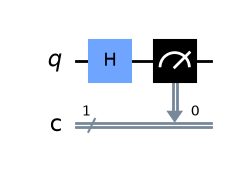

↑ the test circuit: H prepares |+⟩, the error channel (when present) acts right after the H, then a Z-basis measurement
Ideal: {'0': 5081, '1': 4919}
Bit flip (p=10%): {'0': 4985, '1': 5015}
Phase flip (p=10%): {'1': 4991, '0': 5009}
Depolarizing (p=10%): {'1': 5103, '0': 4897}


In [2]:
# Visualising the effect of errors on a |+> state
def simulate_error_effect(error, n_shots: int = 10000) -> dict:    # type hints: n_shots is an int (default 10000); the function returns a dict
    """Simulate the effect of an error on the state |+>."""
    qc = QuantumCircuit(1, 1)              # 1 qubit, 1 classical bit
    qc.h(0)  # Prepare |+>
    qc.measure(0, 0)                       # Z-basis measurement: qubit 0 -> classical bit 0

    # Noise model with an error after H
    noise = NoiseModel()                                   # an empty model = ideal simulation
    noise.add_all_qubit_quantum_error(error, ['h'])       # attach `error` after every 'h' gate, on every qubit

    sim = AerSimulator(noise_model=noise)  # the simulator applies the model's errors while it runs
    sampler = SamplerV2()                  # Aer's Sampler primitive
    sampler._backend = sim                 # the author's shortcut: point the sampler at the noisy simulator (documented spelling: SamplerV2.from_backend(sim))

    job = sampler.run([qc], shots=n_shots)                 # run takes a LIST of circuits; shots = number of repetitions
    counts = job.result()[0].data.c.get_counts()           # [0] = first circuit; .data.c = the classical register named 'c' -> {'0': n0, '1': n1}

    return counts

# Test: ideal |+> state (50-50)
print("Effect of different errors on |+>:")
print("=" * 50)                            # a 50-character rule

# No error (reference)
qc_ref = QuantumCircuit(1, 1)
qc_ref.h(0)
qc_ref.measure(0, 0)
display(draw(qc_ref)); print("↑ the test circuit: H prepares |+⟩, the error channel (when present) acts right after the H, then a Z-basis measurement")
sim_ideal = AerSimulator()                 # noise-free simulator (SamplerV2() below defaults to an ideal AerSimulator anyway)
sampler_ideal = SamplerV2()
job_ideal = sampler_ideal.run([qc_ref], shots=10000)
counts_ideal = job_ideal.result()[0].data.c.get_counts()
print(f"Ideal: {counts_ideal}")

# Bit flip with p=10%
bit_flip = pauli_error([('X', 0.1), ('I', 0.9)])         # with probability 0.1 apply X, with 0.9 do nothing (probabilities must sum to 1)
counts_bf = simulate_error_effect(bit_flip)
print(f"Bit flip (p=10%): {counts_bf}")

# Phase flip with p=10%
phase_flip = pauli_error([('Z', 0.1), ('I', 0.9)])       # with probability 0.1 apply Z
counts_pf = simulate_error_effect(phase_flip)
print(f"Phase flip (p=10%): {counts_pf}")

# Depolarizing with p=10%
depol = depolarizing_error(0.1, 1)         # depolarizing_error(p, number_of_qubits): rho -> 0.9 rho + 0.1 I/2
counts_dep = simulate_error_effect(depol)
print(f"Depolarizing (p=10%): {counts_dep}")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `def simulate_error_effect(error, n_shots: int = 10000) -> dict:` | a typed function: `error` is any `QuantumError`, `n_shots` an int with a default, `-> dict` announces the return type (the counts dictionary) |
| `noise.add_all_qubit_quantum_error(error, ['h'])` | the rule "after every `h` gate, on whatever qubit, apply `error`"; the list can name several gates at once |
| `sampler._backend = sim` | the author's way to make the Sampler use the noisy simulator (the leading underscore marks a private attribute; `SamplerV2.from_backend(sim)` is the public way) |
| `job.result()[0].data.c.get_counts()` | SamplerV2 returns one result per circuit; `.data.c` is the classical register `c`; `get_counts()` turns the shots into `{'0': ..., '1': ...}` |
| `pauli_error([('X', 0.1), ('I', 0.9)])` | a stochastic Pauli channel: X with probability 0.1, identity otherwise. Same for Z. `depolarizing_error(0.1, 1)` mixes the state with I/2 |
| all four results are ≈ 5000 / 5000 | the Z-basis measurement of \|+⟩ cannot see any of these errors (box below) — a first lesson: what an error does depends on what you measure |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**Why all four histograms are 50/50.** The state after H is $|+\rangle=\tfrac{1}{\sqrt2}(|0\rangle+|1\rangle)$, whose density matrix is $\rho=\tfrac12\begin{pmatrix}1&1\\1&1\end{pmatrix}$.

- bit flip: $X|+\rangle=|+\rangle$ — the state is an eigenstate of $X$, nothing happens;
- phase flip: $Z|+\rangle=|-\rangle=\tfrac{1}{\sqrt2}(|0\rangle-|1\rangle)$, so $\rho\to 0.9\,|+\rangle\langle+|+0.1\,|-\rangle\langle-|=\tfrac12\begin{pmatrix}1&0.8\\0.8&1\end{pmatrix}$;
- depolarising: $\rho\to 0.9\,\rho+0.1\,\tfrac{I}{2}=\tfrac12\begin{pmatrix}1&0.9\\0.9&1\end{pmatrix}$.

A $Z$-basis measurement only reads the **diagonal** of $\rho$, which is $(\tfrac12,\tfrac12)$ in every case: $P(0)=P(1)=\tfrac12$, i.e. $5000\pm50$ counts out of 10 000 (the standard deviation is $\sqrt{10000\cdot\tfrac14}=50$). The damage is in the **off-diagonal** element (the coherence): $0.5\to0.4$ for the phase flip, $0.5\to0.45$ for depolarising. To see it one must measure in the $X$ basis (an H before the measurement) — task (1) of the 🔬 section does exactly that: it predicts 0 % wrong outcomes for the bit flip, 10 % for the phase flip and 5 % for depolarising.

</details>


<a id='noise_model'></a>
## 3. Building a Noise Model

### Structure of a NoiseModel

A `NoiseModel` in Qiskit Aer contains:
1. **Quantum errors**: errors applied after the gates
2. **Readout errors**: measurement errors
3. **Basis gates**: gates supported by the model

In [3]:
# Let's build a noise model step by step
noise_model = NoiseModel()                                   # start empty

print("Building a NoiseModel")
print("=" * 50)

# 1. Error on 1-qubit gates (all qubits)
error_1q = depolarizing_error(0.001, 1)  # 0.1% error         # 1-qubit depolarising channel, p = 0.001
noise_model.add_all_qubit_quantum_error(error_1q, ['h', 'x', 'y', 'z', 'rx', 'ry', 'rz'])   # attach it after each of these gate names
print("Added 0.1% error on 1-qubit gates")

# 2. Error on 2-qubit gates (all qubits)
error_2q = depolarizing_error(0.01, 2)  # 1% error            # 2-qubit depolarising channel (d = 4), ten times larger: 2q gates are the weak spot
noise_model.add_all_qubit_quantum_error(error_2q, ['cx', 'cz', 'cp'])
print("Added 1% error on 2-qubit gates")

# 3. Measurement error
p_meas_error = 0.02  # 2% error
readout_error = ReadoutError([[1 - p_meas_error, p_meas_error],      # row 0: true |0> -> read 0 with 0.98, read 1 with 0.02
                               [p_meas_error, 1 - p_meas_error]])     # row 1: true |1> -> read 0 with 0.02, read 1 with 0.98
noise_model.add_all_qubit_readout_error(readout_error)               # same confusion matrix on every measured qubit
print("Added 2% measurement error")

# Show the noise model
print(f"\nNoise Model summary:")
print(f"  Basis gates: {noise_model.basis_gates}")              # gates the noisy simulator will accept (noisy gates + Aer defaults)
print(f"  Noise instructions: {noise_model.noise_instructions}")  # instructions that carry an error ('measure' included)
print(f"  Noise qubits: {noise_model.noise_qubits}")           # empty: "all-qubit" errors are not tied to specific qubits


Building a NoiseModel
Added 0.1% error on 1-qubit gates
Added 1% error on 2-qubit gates
Added 2% measurement error

Noise Model summary:
  Basis gates: ['cp', 'cx', 'cz', 'h', 'id', 'rx', 'ry', 'rz', 'sx', 'x', 'y', 'z']
  Noise instructions: ['cp', 'cx', 'cz', 'h', 'measure', 'rx', 'ry', 'rz', 'x', 'y', 'z']
  Noise qubits: []


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `depolarizing_error(0.001, 1)` / `depolarizing_error(0.01, 2)` | one- and two-qubit depolarising channels; realistic ratios: 2-qubit gates are ~10× worse than 1-qubit gates |
| `add_all_qubit_quantum_error(err, [gate names])` | the same error after every listed gate on every qubit (`add_quantum_error(err, gates, qubits)` would target specific qubits) |
| `ReadoutError([[0.98, 0.02], [0.02, 0.98]])` | the confusion matrix: entry `[i][j]` = probability of **reading** `j` when the qubit **is** `i` (rows = true state, each row sums to 1) |
| `add_all_qubit_readout_error(...)` | attach the confusion matrix to every measurement |
| `noise_model.basis_gates` / `.noise_instructions` / `.noise_qubits` | what the model knows: the gate set the simulator must transpile to, which instructions are noisy, and which qubits have qubit-specific errors (none here, hence `[]`) |

</details>


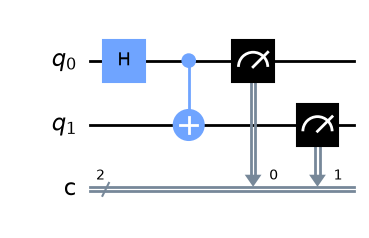

↑ the Bell circuit: H then CNOT give (|00⟩ + |11⟩)/√2; every outcome other than 00 or 11 is an error


Bell State: |00> + |11>
  Ideal: {'00': 2045, '11': 2051}
  Noisy: {'11': 1971, '00': 1942, '01': 91, '10': 92}
  Approximate fidelity: 0.9553


In [4]:
# Comparison: ideal vs noisy circuit
def compare_ideal_noisy(circuit: QuantumCircuit, noise: NoiseModel,
                        shots: int = 4096) -> Tuple[dict, dict]:   # returns a pair of dicts (ideal counts, noisy counts)
    """
    Compare ideal and noisy execution.

    Returns:
        (counts_ideal, counts_noisy)
    """
    # Ideal simulator
    sim_ideal = AerSimulator()
    sampler_ideal = SamplerV2()
    pm = generate_preset_pass_manager(optimization_level=1, backend=sim_ideal)   # light transpilation to the simulator's gate set
    transpiled = pm.run(circuit)

    job_ideal = sampler_ideal.run([transpiled], shots=shots)

    # Extract the name of the classical register
    creg_name = circuit.cregs[0].name if circuit.cregs else 'c'            # conditional expression: first classical register's name, or 'c'
    counts_ideal = job_ideal.result()[0].data.__getattribute__(creg_name).get_counts()   # attribute lookup by name (same as getattr(data, creg_name))

    # Noisy simulator
    sim_noisy = AerSimulator(noise_model=noise)
    sampler_noisy = SamplerV2()
    sampler_noisy._backend = sim_noisy                                      # same shortcut as before: sampler on the noisy simulator

    job_noisy = sampler_noisy.run([transpiled], shots=shots)                # the SAME transpiled circuit, so only the noise differs
    counts_noisy = job_noisy.result()[0].data.__getattribute__(creg_name).get_counts()

    return counts_ideal, counts_noisy                                       # a tuple; unpacked below as `ideal, noisy = ...`

# Test: Bell state
qc_bell = QuantumCircuit(2, 2, name='Bell')
qc_bell.h(0)
qc_bell.cx(0, 1)
qc_bell.measure([0, 1], [0, 1])            # measure(qubits, bits): qubit 0 -> bit 0, qubit 1 -> bit 1
display(draw(qc_bell)); print("↑ the Bell circuit: H then CNOT give (|00⟩ + |11⟩)/√2; every outcome other than 00 or 11 is an error")

ideal, noisy = compare_ideal_noisy(qc_bell, noise_model)

print("Bell State: |00> + |11>")
print(f"  Ideal: {ideal}")
print(f"  Noisy: {noisy}")

# Compute an approximate fidelity
total = sum(noisy.values())                             # total shots
correct = noisy.get('00', 0) + noisy.get('11', 0)       # .get(key, 0): 0 if the outcome never appeared
fidelity = correct / total                              # fraction of "right" outcomes — a classical proxy of the state fidelity
print(f"  Approximate fidelity: {fidelity:.4f}")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `-> Tuple[dict, dict]` | type hint: the function returns a 2-tuple of dicts; the caller unpacks it as `ideal, noisy = compare_ideal_noisy(...)` |
| `pm = generate_preset_pass_manager(optimization_level=1, backend=sim_ideal)`; `pm.run(circuit)` | transpile once, then run the same transpiled circuit ideally and noisily — a fair comparison where only the noise model changes |
| `circuit.cregs[0].name` + `data.__getattribute__(creg_name)` | the Sampler stores the counts under the name of the classical register, so the register name is looked up at run time instead of hard-coding `.c` |
| `noisy.get('00', 0) + noisy.get('11', 0)` | the number of outcomes compatible with the Bell state; divided by the shots it gives the "approximate fidelity" (the probability of a correct bitstring) |
| outcomes `01` / `10` in the noisy run | they come from the 2-qubit depolarising error on the CX and from readout flips; the box below predicts ≈ 0.956 |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**Predicting the Bell fidelity** with the model of the previous cell (1q depolarising 0.1 %, 2q depolarising 1 %, readout 2 %).

- Readout: both bits must be read correctly, $0.98^2=0.9604$.
- The 2-qubit depolarising error on the CX: $\rho\to0.99\,\rho+0.01\,\tfrac{I}{4}$; the maximally mixed state $I/4$ gives 00 or 11 with probability $\tfrac12$, so the fraction of correct outcomes becomes $0.99+0.01\cdot\tfrac12=1-\tfrac{p}{2}=0.995$.
- The 1-qubit depolarising error on the H (before the CX) is *invisible* here: $\tfrac{I}{2}\otimes|0\rangle\langle0|$ is mapped by the CX to $\tfrac12(|00\rangle\langle00|+|11\rangle\langle11|)$, still a "correct" outcome.

$$F\approx0.9604\times0.995=0.9556$$

with a statistical spread of $\sqrt{F(1-F)/4096}\approx0.003$. The cell prints a value within that band of 0.956.

</details>


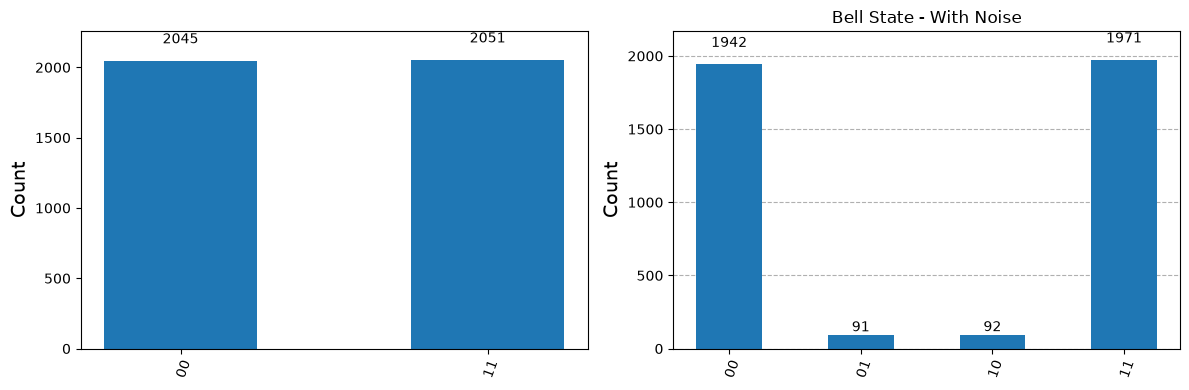

↑ left: only 00 and 11; right: the same circuit under the noise model — the two small bars 01 and 10 are the ~4 % of shots lost to readout flips and the CX error


In [5]:
# Visualisation
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))   # one figure, two axes side by side

plot_histogram(ideal, ax=ax1, title='Bell State - Ideal')      # ax=...: draw into an existing axis instead of a new figure
plot_histogram(noisy, ax=ax2, title='Bell State - With Noise')

plt.tight_layout()
plt.show()
print("↑ left: only 00 and 11; right: the same circuit under the noise model — the two small bars 01 and 10 are the ~4 % of shots lost to readout flips and the CX error")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))` | a 1×2 grid of axes; tuple unpacking gives the two axes separate names |
| `plot_histogram(counts, ax=ax1, title=...)` | Qiskit's histogram drawn into a chosen axis, so two count dictionaries can be compared in one figure |

</details>


<a id='depolarizing'></a>
## 4. Depolarizing Errors

### Definition

The depolarizing error "mixes" the state with the maximally mixed state:

$$\mathcal{E}_{dep}(\rho) = (1-p)\rho + \frac{p}{d}I$$

For 1 qubit ($d=2$):
$$\mathcal{E}_{dep}(\rho) = (1-p)\rho + \frac{p}{3}(X\rho X + Y\rho Y + Z\rho Z)$$

For 2 qubits ($d=4$):
$$\mathcal{E}_{dep}(\rho) = (1-p)\rho + \frac{p}{15}\sum_{P} P\rho P$$

In [6]:
def study_depolarizing_effect(p_range: List[float], circuit: QuantumCircuit,
                               expected_states: List[str]) -> dict:   # List[float] / List[str]: hints for "a list of floats / of strings"
    """
    Study the effect of the depolarizing error as p varies.

    Args:
        p_range: List of error probabilities
        circuit: Circuit to test
        expected_states: Expected states (to compute the fidelity)

    Returns:
        Dictionary with the fidelity for each p
    """
    results = {'p': [], 'fidelity': []}        # a dict of two parallel lists, filled in the loop
    creg_name = circuit.cregs[0].name          # name of the classical register (here 'c')

    for p in p_range:
        # Create the noise model
        noise = NoiseModel()                                                         # a fresh model for every p
        noise.add_all_qubit_quantum_error(depolarizing_error(p, 1), ['h', 'x'])     # 1q depolarising with the same p ...
        noise.add_all_qubit_quantum_error(depolarizing_error(p, 2), ['cx'])         # ... and 2q depolarising with the same p

        # Simulate
        sim = AerSimulator(noise_model=noise)
        sampler = SamplerV2()
        sampler._backend = sim

        job = sampler.run([circuit], shots=4096)
        counts = job.result()[0].data.__getattribute__(creg_name).get_counts()

        # Compute the fidelity
        total = sum(counts.values())
        correct = sum(counts.get(s, 0) for s in expected_states)   # generator expression: add up the counts of all expected bitstrings
        fidelity = correct / total

        results['p'].append(p)                 # grow the two lists in step
        results['fidelity'].append(fidelity)

    return results

# Study for the Bell state
p_values = [0, 0.01, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3]
bell_results = study_depolarizing_effect(p_values, qc_bell, ['00', '11'])

print("Depolarizing effect on the Bell state:")
print(f"{'p':>8} {'Fidelity':>10}")         # format spec >8 / >10: right-align in a field of 8 / 10 characters
print("-" * 20)
for p, f in zip(bell_results['p'], bell_results['fidelity']):   # zip walks the two lists together
    print(f"{p:>8.2f} {f:>10.4f}")           # .2f / .4f: 2 / 4 decimals


Depolarizing effect on the Bell state:
       p   Fidelity
--------------------
    0.00     1.0000
    0.01     0.9968
    0.02     0.9905
    0.05     0.9731
    0.10     0.9497
    0.15     0.9219
    0.20     0.9001
    0.30     0.8557


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `p_range: List[float]`, `expected_states: List[str]`, `-> dict` | typed signature: lists of floats / strings in, a dict out — the `typing` names imported at the top |
| `results = {'p': [], 'fidelity': []}` + `.append(...)` | the author's "dict of lists" return pattern: two columns that grow together and are later read with `zip` |
| `depolarizing_error(p, 1)` on `['h', 'x']`, `depolarizing_error(p, 2)` on `['cx']` | the same probability p for 1- and 2-qubit gates, swept from 0 to 0.3 |
| `sum(counts.get(s, 0) for s in expected_states)` | fidelity proxy = fraction of shots landing on an expected bitstring (`00` or `11`) |
| `f"{p:>8.2f} {f:>10.4f}"` | f-string format specs: width, alignment (`>` = right) and number of decimals |
| the table | fidelity falls linearly: F ≈ 1 − p/2 (box below), because for the Bell circuit only the CX error is visible |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**The straight line $F = 1 - p/2$.** The Bell circuit has one CX. The 2-qubit depolarising channel replaces the state by $I/4$ with probability $p$, and $I/4$ still yields 00 or 11 half of the time:

$$F(p) = (1-p) + p\cdot\tfrac12 = 1-\frac{p}{2}.$$

The 1-qubit depolarising error on the H (same $p$) does not change the 00/11 statistics, as shown in the previous box, and there is no X gate in the circuit. Check against the table: $p=0.1\to0.950$, $p=0.2\to0.900$, $p=0.3\to0.850$ (each entry has a statistical uncertainty of about $\pm0.005$ with 4096 shots). Depolarising noise is therefore *linear* in $p$ for a shallow circuit; for a circuit with $m$ two-qubit gates the correct fraction is roughly $(1-p/2)^m$ — see the GHZ and Grover sections.

</details>


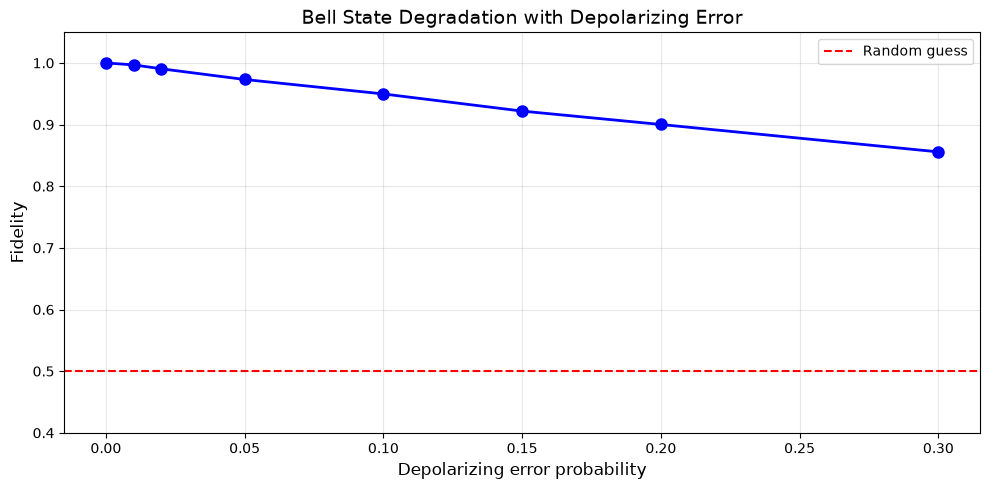

↑ fidelity of the Bell state vs the depolarising probability: a straight line of slope −1/2 (F = 1 − p/2); the dashed line is the 50 % floor of a completely mixed 2-qubit state


In [7]:
# Plot: fidelity vs depolarizing error
plt.figure(figsize=(10, 5))

plt.plot(bell_results['p'], bell_results['fidelity'], 'bo-', linewidth=2, markersize=8)   # 'bo-': blue, circle markers, solid line
plt.axhline(y=0.5, color='r', linestyle='--', label='Random guess')                       # horizontal reference: a maximally mixed state gives F = 0.5

plt.xlabel('Depolarizing error probability', fontsize=12)
plt.ylabel('Fidelity', fontsize=12)
plt.title('Bell State Degradation with Depolarizing Error', fontsize=14)
plt.legend()
plt.grid(True, alpha=0.3)
plt.ylim(0.4, 1.05)

plt.tight_layout()
plt.show()
print("↑ fidelity of the Bell state vs the depolarising probability: a straight line of slope −1/2 (F = 1 − p/2); the dashed line is the 50 % floor of a completely mixed 2-qubit state")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `plt.plot(x, y, 'bo-', ...)` | matplotlib format string: colour **b**lue, marker **o**, line style **-** |
| `plt.axhline(y=0.5, ...)` | horizontal reference line: fidelity 0.5 = what a completely depolarised Bell pair would give (00 or 11 by chance) |
| `plt.ylim(0.4, 1.05)` | fix the y-range so the slope is readable |

</details>


<a id='thermal'></a>
## 5. Thermal Relaxation (T1/T2)

### Physics of relaxation

**T1 (Longitudinal relaxation)**: decay of |1> towards |0>
- Cause: spontaneous emission, interaction with the environment
- Effect: |1> -> |0> with probability 1 - exp(-t/T1)

**T2 (Dephasing)**: loss of phase coherence
- Cause: fluctuations of the local magnetic field
- Effect: |+> -> mixed state
- Relation: T2 <= 2*T1 (physical limit)

In [8]:
def create_thermal_noise_model(t1: float, t2: float,
                                gate_times: dict = None) -> NoiseModel:   # gate_times defaults to None, then filled below (never use a mutable {} as a default)
    """
    Create a noise model with thermal relaxation.

    Args:
        t1: T1 time in nanoseconds
        t2: T2 time in nanoseconds (must be <= 2*T1)
        gate_times: Dictionary {gate_name: time_ns}

    Returns:
        Configured NoiseModel
    """
    if gate_times is None:
        # Typical times for superconducting hardware
        gate_times = {
            'h': 35,      # ~35 ns
            'x': 35,
            'y': 35,
            'z': 0,       # Virtual (no time)             # Z rotations are done in software (frame change): zero duration, no decay
            'rx': 35,
            'ry': 35,
            'rz': 0,
            'cx': 300,    # ~300 ns (2q gate is slower)
            'cz': 300,
            'measure': 1000  # ~1 us
        }

    noise = NoiseModel()

    # Add a thermal error for every gate type
    for gate, time in gate_times.items():                  # .items(): (key, value) pairs of the dict
        if time > 0:                                       # zero-duration gates get no error
            if gate in ['cx', 'cz', 'cp']:
                # 2-qubit gate: apply a thermal error to both qubits
                error = thermal_relaxation_error(t1, t2, time).tensor(      # thermal_relaxation_error(T1, T2, gate_time) is a 1-qubit channel ...
                        thermal_relaxation_error(t1, t2, time))             # ... .tensor() glues two of them into a 2-qubit channel (one per qubit)
                noise.add_all_qubit_quantum_error(error, [gate])
            else:
                # 1-qubit gate
                error = thermal_relaxation_error(t1, t2, time)
                noise.add_all_qubit_quantum_error(error, [gate])

    return noise

# Create a noise model with T1=100us, T2=80us (realistic values)
T1 = 100e3  # 100 us in ns                 # 100e3 = 100 000 ns: all times in this notebook are in nanoseconds
T2 = 80e3   # 80 us in ns

thermal_noise = create_thermal_noise_model(T1, T2)

print(f"Noise Model with Thermal Relaxation")
print(f"  T1 = {T1/1000:.0f} us")
print(f"  T2 = {T2/1000:.0f} us")


Noise Model with Thermal Relaxation
  T1 = 100 us
  T2 = 80 us


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `thermal_relaxation_error(t1, t2, time)` | the T1/T2 channel for a gate lasting `time` ns: amplitude damping with probability 1 − e^(−t/T1) plus dephasing so that coherences decay as e^(−t/T2); it raises an error if T2 > 2·T1 |
| `.tensor(...)` | tensor product of two 1-qubit errors → a 2-qubit error acting independently on each qubit of a CX/CZ (the slow gate: 300 ns vs 35 ns) |
| `gate_times: dict = None` + `if gate_times is None:` | the standard Python idiom for an optional dictionary argument with a default built inside the function |
| `'z': 0`, `'rz': 0` | virtual Z rotations take no time on superconducting hardware, so they get no thermal error (`if time > 0`) |
| `T1 = 100e3`, `T2 = 80e3` | 100 µs and 80 µs written in ns; T2 < 2·T1 as physics requires (next box) |

</details>


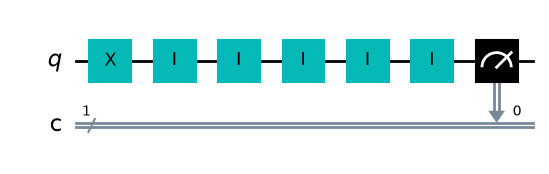

↑ the T1 test circuit (shown with 5 of the 100 identity gates): X prepares |1⟩, each identity is 50 ns of waiting with T1 decay attached, then a measurement


T1 decay (|1> survival probability):
   T1 (us)     P(|1>)
----------------------
         1     0.0063
         5     0.3616
        10     0.6013
        20     0.7686
        50     0.8906
       100     0.9446
       200     0.9773


In [9]:
# Study of the effect of T1 on |1>
def study_t1_decay(t1_values: List[float], circuit_depth: int = 100) -> dict:
    """
    Study the T1 decay of |1> as T1 varies.
    """
    results = {'t1': [], 'p_survive': []}      # dict-of-lists return pattern again

    # Circuit: prepare |1> and apply identities (to accumulate time)
    qc = QuantumCircuit(1, 1)
    qc.x(0)  # Prepare |1>
    for _ in range(circuit_depth):             # `_`: loop variable we do not use
        qc.id(0)  # Identity (but accumulates decoherence time)    # id = "wait": does nothing but carries a duration in the noise model
    qc.measure(0, 0)

    for t1 in t1_values:
        # Noise model
        noise = NoiseModel()
        # 50 ns per identity gate (simulates the idle time)
        error = thermal_relaxation_error(t1, t1, 50)  # T2=T1 for simplicity     # 50 ns of relaxation per gate
        noise.add_all_qubit_quantum_error(error, ['id', 'x'])                   # after the X and after each of the 100 identities: 101 × 50 ns in total

        sim = AerSimulator(noise_model=noise)
        sampler = SamplerV2()
        sampler._backend = sim

        job = sampler.run([qc], shots=4096)
        counts = job.result()[0].data.c.get_counts()

        total = sum(counts.values())
        p_1 = counts.get('1', 0) / total       # survival probability of |1>

        results['t1'].append(t1)
        results['p_survive'].append(p_1)

    return results

demo = QuantumCircuit(1, 1); demo.x(0)
for _ in range(5): demo.id(0)
demo.measure(0, 0)
display(draw(demo)); print("↑ the T1 test circuit (shown with 5 of the 100 identity gates): X prepares |1⟩, each identity is 50 ns of waiting with T1 decay attached, then a measurement")

# Study with different T1
t1_range = [1e3, 5e3, 10e3, 20e3, 50e3, 100e3, 200e3]  # ns      # 1 µs ... 200 µs
t1_results = study_t1_decay(t1_range, circuit_depth=100)

print("T1 decay (|1> survival probability):")
print(f"{'T1 (us)':>10} {'P(|1>)':>10}")
print("-" * 22)
for t1, p in zip(t1_results['t1'], t1_results['p_survive']):
    print(f"{t1/1000:>10.0f} {p:>10.4f}")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `qc.id(0)` × 100 | identity gates are the way to make a circuit *wait*: they do nothing to the state, but the noise model attaches 50 ns of T1 decay to each of them |
| `thermal_relaxation_error(t1, t1, 50)` | T2 = T1 for simplicity (allowed: T2 ≤ 2·T1); only the populations matter here, since \|1⟩ is measured in the Z basis |
| `add_all_qubit_quantum_error(error, ['id', 'x'])` | the X gate decays too, so the total idle time is 101 × 50 ns = 5.05 µs |
| `p_1 = counts.get('1', 0) / total` | the measured survival probability P(\|1⟩), to be compared with e^(−t/T1) in the box below |
| `for t1, p in zip(...)` | walk the two result lists together to print the table |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**$T_1$ decay $e^{-t/T_1}$.** A qubit in $|1\rangle$ relaxes to $|0\rangle$ with probability $1-e^{-t/T_1}$ after a time $t$; the circuit waits $t = 101\times50\,\text{ns} = 5.05\,\mu\text{s}$ (the X gate plus 100 identities). The survival probability is

$$P(|1\rangle)=e^{-t/T_1}:\qquad
\begin{array}{c|ccccccc}
T_1\ (\mu s) & 1 & 5 & 10 & 20 & 50 & 100 & 200\\ \hline
e^{-5.05/T_1} & 0.006 & 0.364 & 0.604 & 0.777 & 0.904 & 0.951 & 0.975
\end{array}$$

The printed column agrees within the statistical spread of 4096 shots ($\pm0.008$ at $P\approx0.6$). The dashed "Theory" curve of the next cell uses $t=5.0\,\mu$s (100 identities), a 1 % difference.

**Why $T_2\le2T_1$.** $T_1$ destroys the populations, $T_2$ the coherences. A pure relaxation event also randomises the phase, so the coherence decays at least at half the relaxation rate: $1/T_2 = 1/(2T_1) + 1/T_\varphi$ with $T_\varphi\ge0$ the pure-dephasing time. Hence $T_2\le2T_1$, with equality only if there is no pure dephasing; `thermal_relaxation_error` refuses $T_2>2T_1$. With $T_2=T_1$ (this cell) the pure-dephasing rate equals $1/(2T_1)$.

</details>


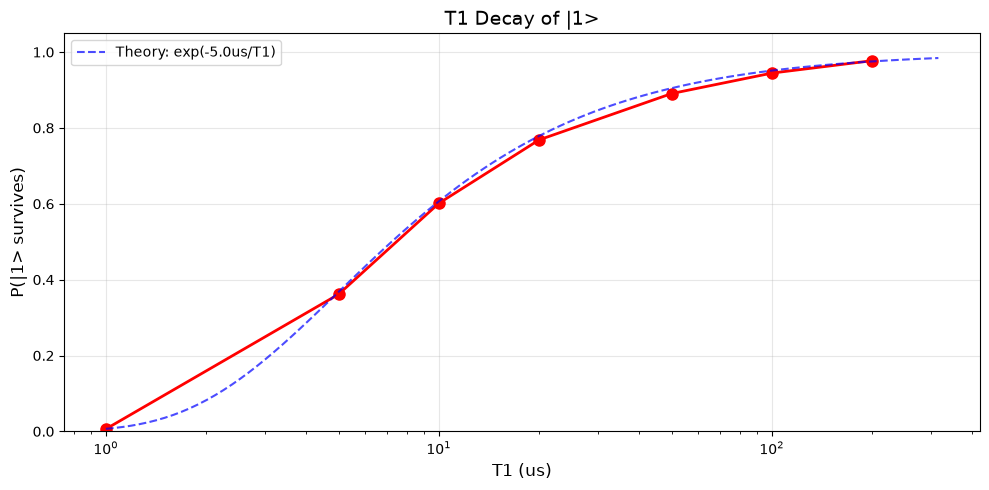

↑ measured survival of |1⟩ (red) against the exponential law exp(−t/T1) (dashed): T1 must be much longer than the circuit time (5 µs here) for the qubit to keep its value


In [10]:
# Plot: T1 decay
plt.figure(figsize=(10, 5))

t1_us = [t/1000 for t in t1_results['t1']]                          # list comprehension: ns -> µs
plt.semilogx(t1_us, t1_results['p_survive'], 'ro-', linewidth=2, markersize=8)   # logarithmic x axis: T1 spans two decades

# Theory line: P = exp(-t_circuit/T1)
t_circuit = 100 * 50  # 100 identity gates x 50 ns
t1_theory = np.logspace(0, 2.5, 100) * 1000  # 1 us to ~300 us in ns      # 100 log-spaced values of T1
p_theory = np.exp(-t_circuit / t1_theory)                                   # vectorised: one exp per T1 value
plt.semilogx([t/1000 for t in t1_theory], p_theory, 'b--',
             label=f'Theory: exp(-{t_circuit/1000:.1f}us/T1)', alpha=0.7)

plt.xlabel('T1 (us)', fontsize=12)
plt.ylabel('P(|1> survives)', fontsize=12)
plt.title('T1 Decay of |1>', fontsize=14)
plt.legend()
plt.grid(True, alpha=0.3)
plt.ylim(0, 1.05)

plt.tight_layout()
plt.show()
print("↑ measured survival of |1⟩ (red) against the exponential law exp(−t/T1) (dashed): T1 must be much longer than the circuit time (5 µs here) for the qubit to keep its value")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `plt.semilogx(...)` | like `plot` but with a logarithmic x axis, natural for a parameter that spans 1 µs … 200 µs |
| `np.logspace(0, 2.5, 100) * 1000` | 100 values from 10⁰ to 10^2.5 µs (1 … 316 µs), converted to ns |
| `np.exp(-t_circuit / t1_theory)` | NumPy applies the exponential to the whole array at once — the theoretical curve |

</details>


<a id='readout'></a>
## 6. Measurement (Readout) Errors

### Definition

Measurement errors are described by a **confusion matrix**:

$$M = \begin{pmatrix} P(0|0) & P(0|1) \\ P(1|0) & P(1|1) \end{pmatrix}$$

where P(m|s) is the probability of measuring m given the true state s.

Typically P(0|1) > P(1|0), because the decay towards |0> also happens during the measurement.

In [11]:
def create_asymmetric_readout_error(p_0_given_1: float,
                                     p_1_given_0: float) -> ReadoutError:
    """
    Create an asymmetric readout error.

    Args:
        p_0_given_1: P(measure 0 | state is 1)
        p_1_given_0: P(measure 1 | state is 0)

    Returns:
        ReadoutError
    """
    confusion_matrix = [
        [1 - p_1_given_0, p_1_given_0],    # Given state |0>     # row 0 = true |0>: [P(read 0), P(read 1)]
        [p_0_given_1, 1 - p_0_given_1]     # Given state |1>     # row 1 = true |1>: [P(read 0), P(read 1)]
    ]
    return ReadoutError(confusion_matrix)   # rows = true state, columns = measured value (each row sums to 1)

# Test readout error
print("Study of readout errors")
print("=" * 50)

# Symmetric error
p_error = 0.05  # 5%
readout_sym = create_asymmetric_readout_error(p_error, p_error)

# Asymmetric error (more realistic)
readout_asym = create_asymmetric_readout_error(0.08, 0.02)  # 8% and 2%   # |1> is misread more often: it can decay to |0> during the (long) measurement

# Test on the states |0> and |1>
for name, error in [('Symmetric (5%/5%)', readout_sym),
                    ('Asymmetric (8%/2%)', readout_asym)]:      # loop over (label, error) pairs
    print(f"\n{name}:")

    noise = NoiseModel()
    noise.add_all_qubit_readout_error(error)                 # readout error only: the gates are perfect

    for state, prep in [('|0>', []), ('|1>', ['x'])]:        # prepare |0> (no gate) or |1> (an X)
        qc = QuantumCircuit(1, 1)
        for gate in prep:
            getattr(qc, gate)(0)                             # getattr(qc, 'x')(0) is the same as qc.x(0): call a method chosen by its name
        qc.measure(0, 0)

        sim = AerSimulator(noise_model=noise)
        sampler = SamplerV2()
        sampler._backend = sim

        job = sampler.run([qc], shots=10000)
        counts = job.result()[0].data.c.get_counts()

        print(f"  {state}: {counts}")


Study of readout errors

Symmetric (5%/5%):
  |0>: {'1': 507, '0': 9493}
  |1>: {'1': 9503, '0': 497}

Asymmetric (8%/2%):
  |0>: {'0': 9784, '1': 216}
  |1>: {'1': 9193, '0': 807}


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `confusion_matrix = [[1 − p(1\|0), p(1\|0)], [p(0\|1), 1 − p(0\|1)]]` | Aer's convention: row = the qubit's true state, column = the bit that is read. Note that the matrix $M$ written in the markdown above is its **transpose** (columns = true state) — same numbers, different layout |
| `create_asymmetric_readout_error(0.08, 0.02)` | P(read 0 \| is 1) = 8 % > P(read 1 \| is 0) = 2 %: the realistic asymmetry, because \|1⟩ can relax to \|0⟩ during the ~1 µs measurement |
| `for state, prep in [('\|0>', []), ('\|1>', ['x'])]` | a tiny calibration experiment: prepare each basis state and count how often it is misread — exactly how a real confusion matrix is measured |
| `getattr(qc, gate)(0)` | method lookup by name: a string `'x'` becomes the call `qc.x(0)` |
| `noise.add_all_qubit_readout_error(error)` alone | a model with readout error only, so the counts measure the confusion matrix directly |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**Reading the confusion matrix.** With 10 000 shots the expected counts are simply $10000\cdot M_{ij}$:

- symmetric, $M=\begin{pmatrix}0.95&0.05\\0.05&0.95\end{pmatrix}$: prepared $|0\rangle\to$ 9500 "0" + 500 "1"; prepared $|1\rangle\to$ 500 "0" + 9500 "1";
- asymmetric, $M=\begin{pmatrix}0.98&0.02\\0.08&0.92\end{pmatrix}$ (rows = true state): $|0\rangle\to$ 9800 + 200; $|1\rangle\to$ 800 "0" + 9200 "1".

The binomial spread is $\sqrt{10000\cdot0.05\cdot0.95}\approx22$ counts (symmetric) and $\sqrt{10000\cdot0.08\cdot0.92}\approx27$ (asymmetric, $|1\rangle$ row), so the printed numbers should sit within a few tens of these values. For $n$ measured qubits with independent errors the full matrix is $M^{\otimes n}$ — task (2) of the 🔬 section uses this to *undo* the readout error.

</details>


<a id='complete'></a>
## 7. Complete Noise Model

Let's combine all the error types into a realistic model.

In [12]:
def create_realistic_noise_model(
    t1: float = 100e3,           # T1 in ns
    t2: float = 80e3,            # T2 in ns
    p_depol_1q: float = 0.001,   # 1q depolarizing error
    p_depol_2q: float = 0.01,    # 2q depolarizing error
    p_readout_0: float = 0.02,   # P(1|0)
    p_readout_1: float = 0.05,   # P(0|1)
    gate_times: dict = None
) -> NoiseModel:                 # keyword arguments with defaults: every parameter can be overridden by name
    """
    Create a realistic noise model combining all the error types.

    Args:
        t1, t2: Relaxation times in ns
        p_depol_1q, p_depol_2q: Depolarizing error probabilities
        p_readout_0, p_readout_1: Readout error probabilities
        gate_times: Gate times in ns

    Returns:
        Complete NoiseModel
    """
    if gate_times is None:
        gate_times = {
            'id': 50,
            'h': 50,
            'x': 50,
            'y': 50,
            'z': 0,
            'sx': 50,
            'rx': 50,
            'ry': 50,
            'rz': 0,
            'cx': 300,
            'cz': 300,
        }

    noise = NoiseModel()

    # 1. Errors on 1-qubit gates: depolarizing + thermal
    gates_1q = ['id', 'h', 'x', 'y', 'sx', 'rx', 'ry']
    for gate in gates_1q:
        if gate in gate_times and gate_times[gate] > 0:
            # Combine depolarizing and thermal
            error_depol = depolarizing_error(p_depol_1q, 1)
            error_thermal = thermal_relaxation_error(t1, t2, gate_times[gate])
            combined = error_depol.compose(error_thermal)            # .compose(): apply one channel AFTER the other (a single combined QuantumError)
            noise.add_all_qubit_quantum_error(combined, [gate])

    # 2. Errors on 2-qubit gates: depolarizing + thermal
    gates_2q = ['cx', 'cz']
    for gate in gates_2q:
        if gate in gate_times and gate_times[gate] > 0:
            error_depol = depolarizing_error(p_depol_2q, 2)
            error_thermal = thermal_relaxation_error(t1, t2, gate_times[gate]).tensor(      # one thermal channel per qubit of the gate ...
                           thermal_relaxation_error(t1, t2, gate_times[gate]))              # ... tensored into a 2-qubit channel
            combined = error_depol.compose(error_thermal)
            noise.add_all_qubit_quantum_error(combined, [gate])

    # 3. Asymmetric readout error
    readout = create_asymmetric_readout_error(p_readout_1, p_readout_0)   # P(0|1) first, P(1|0) second (see the function above)
    noise.add_all_qubit_readout_error(readout)

    return noise

# Create a realistic noise model
realistic_noise = create_realistic_noise_model(      # override the defaults by keyword: a slightly better machine than the defaults
    t1=100e3, t2=80e3,
    p_depol_1q=0.0005, p_depol_2q=0.005,
    p_readout_0=0.015, p_readout_1=0.04
)

print("Realistic Noise Model created")
print(f"  Basis gates: {realistic_noise.basis_gates}")


Realistic Noise Model created
  Basis gates: ['cx', 'cz', 'h', 'id', 'rx', 'ry', 'rz', 'sx', 'x', 'y']


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `def create_realistic_noise_model(t1: float = 100e3, ..., gate_times: dict = None) -> NoiseModel` | a typed signature with defaults: callers pass only what they want to change, by keyword (`p_depol_2q=0.005`) |
| `error_depol.compose(error_thermal)` | channel composition: the gate error (depolarising) followed by the decay during the gate (thermal) — one `QuantumError` to attach |
| `thermal(...).tensor(thermal(...))` then `.compose` with the 2-qubit depolarising | the full 2-qubit gate error: each qubit decays for 300 ns and the pair is depolarised with 0.5 % |
| `create_asymmetric_readout_error(p_readout_1, p_readout_0)` | readout 1.5 % / 4 %: P(read 1 \| is 0) = 0.015, P(read 0 \| is 1) = 0.04 |
| `realistic_noise.basis_gates` | the gate set Aer will transpile every circuit to before simulating it — a `ccz` or `mcx` in a later circuit is unrolled into these gates, and the errors apply to the unrolled gates |

</details>


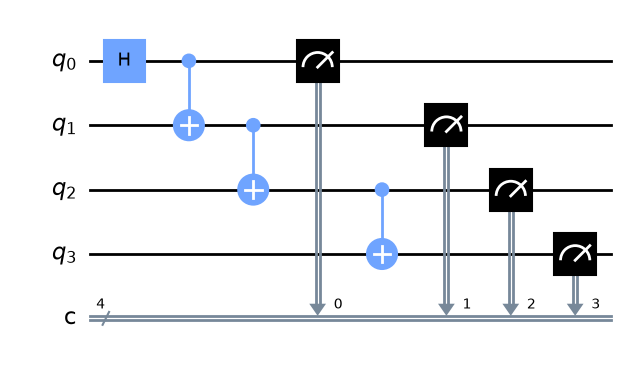

↑ GHZ on 4 qubits: H on qubit 0, then a chain of CNOTs spreads the superposition: (|0000⟩ + |1111⟩)/√2 — every extra qubit costs one more noisy CX and one more noisy readout
GHZ State: Fidelity vs Number of Qubits
N qubits   Ideal fidelity     Noisy fidelity    
----------------------------------------------
2          1.0000             0.9460            


3          1.0000             0.9070            
4          1.0000             0.8667            


5          1.0000             0.8501            


6          1.0000             0.8269            


In [13]:
# Test on the GHZ state (very sensitive to noise)
def create_ghz(n_qubits: int) -> QuantumCircuit:
    """Create an n-qubit GHZ state."""
    qc = QuantumCircuit(n_qubits, n_qubits)
    qc.h(0)
    for i in range(n_qubits - 1):
        qc.cx(i, i + 1)                    # a chain of CNOTs: n − 1 two-qubit gates
    qc.measure(range(n_qubits), range(n_qubits))
    return qc

display(draw(create_ghz(4))); print("↑ GHZ on 4 qubits: H on qubit 0, then a chain of CNOTs spreads the superposition: (|0000⟩ + |1111⟩)/√2 — every extra qubit costs one more noisy CX and one more noisy readout")

# Ideal vs noisy comparison for GHZ states of different size
print("GHZ State: Fidelity vs Number of Qubits")
print("=" * 50)
print(f"{'N qubits':<10} {'Ideal fidelity':<18} {'Noisy fidelity':<18}")   # <10: left-align in 10 characters
print("-" * 46)

ghz_fidelities = []                        # list of (n, f_ideal, f_noisy) tuples, used by the plot below

for n in [2, 3, 4, 5, 6]:
    ghz_circuit = create_ghz(n)
    expected = ['0' * n, '1' * n]          # string repetition: '0' * 3 == '000'

    # Ideal
    sim_ideal = AerSimulator()
    sampler_ideal = SamplerV2()
    job_i = sampler_ideal.run([ghz_circuit], shots=4096)
    counts_i = job_i.result()[0].data.c.get_counts()
    f_ideal = sum(counts_i.get(s, 0) for s in expected) / sum(counts_i.values())

    # Noisy
    sim_noisy = AerSimulator(noise_model=realistic_noise)
    sampler_noisy = SamplerV2()
    sampler_noisy._backend = sim_noisy
    job_n = sampler_noisy.run([ghz_circuit], shots=4096)
    counts_n = job_n.result()[0].data.c.get_counts()
    f_noisy = sum(counts_n.get(s, 0) for s in expected) / sum(counts_n.values())

    ghz_fidelities.append((n, f_ideal, f_noisy))
    print(f"{n:<10} {f_ideal:<18.4f} {f_noisy:<18.4f}")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `create_ghz(n)` | H + a chain of n − 1 CNOTs; the fidelity proxy counts the shots on `'0'*n` or `'1'*n` |
| `expected = ['0' * n, '1' * n]` | string repetition builds the two correct bitstrings for any n |
| `ghz_fidelities.append((n, f_ideal, f_noisy))` | a list of 3-tuples: one row per n, unpacked by the plotting cell with list comprehensions |
| ideal column = 1.0000 | the ideal simulator never leaves the {00…0, 11…1} subspace |
| noisy column falls with n | each extra qubit adds one noisy CX (≈ 0.5 % + 300 ns of decay) and one more readout that can flip (1.5 % / 4 %): the box below estimates the trend |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**Estimating the GHZ fidelity.** Half of the shots are all-0 (each bit read correctly with $0.985$) and half all-1 (each correct with $0.96$), so the readout alone gives

$$F_{\rm ro}(n)=\tfrac12\left(0.985^n+0.96^n\right):\quad F_{\rm ro}(2)=0.946,\ F_{\rm ro}(4)=0.895,\ F_{\rm ro}(6)=0.848.$$

Each of the $n-1$ CX gates costs a factor $\approx(1-0.005/2)\,(1-0.003)\approx0.9945$ (depolarising $p/2$, plus $300\,$ns of $T_1$ relaxation on the $|1\rangle$ components: $1-e^{-300/100000}\approx0.003$), while the 1-qubit errors (0.05 %, 50 ns) are negligible:

$$F(n)\approx F_{\rm ro}(n)\times0.9945^{\,n-1}:\quad F(2)\approx0.941,\ F(4)\approx0.880,\ F(6)\approx0.825.$$

The printed "Noisy fidelity" column follows this trend to within ±0.01 — readout is the dominant loss for this model, which is why readout-error mitigation (🔬 task 2) pays off.

</details>


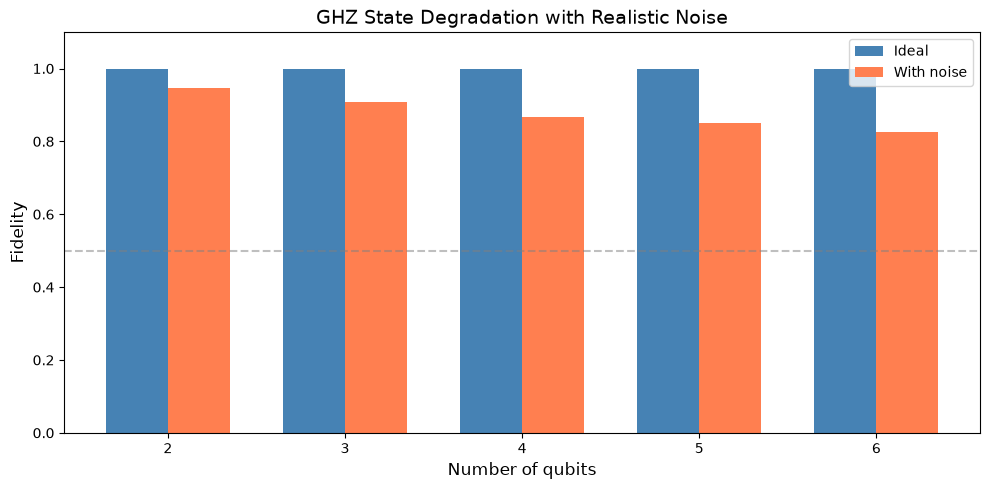

↑ ideal (blue) vs realistic-noise (orange) GHZ fidelity for 2 … 6 qubits: the loss grows with every added CX and readout; the dashed line marks a 50 % random-level reference


In [14]:
# Plot
fig, ax = plt.subplots(figsize=(10, 5))

ns = [x[0] for x in ghz_fidelities]        # list comprehensions pick one column of the tuples
f_ideal = [x[1] for x in ghz_fidelities]
f_noisy = [x[2] for x in ghz_fidelities]

x = np.arange(len(ns))                     # bar positions 0, 1, 2, ...
width = 0.35

bars1 = ax.bar(x - width/2, f_ideal, width, label='Ideal', color='steelblue')   # shift the two bar groups left/right of each position
bars2 = ax.bar(x + width/2, f_noisy, width, label='With noise', color='coral')

ax.set_xlabel('Number of qubits', fontsize=12)
ax.set_ylabel('Fidelity', fontsize=12)
ax.set_title('GHZ State Degradation with Realistic Noise', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(ns)                     # label the positions with the qubit numbers
ax.legend()
ax.set_ylim(0, 1.1)
ax.axhline(y=0.5, color='gray', linestyle='--', alpha=0.5, label='Random')

plt.tight_layout()
plt.show()
print("↑ ideal (blue) vs realistic-noise (orange) GHZ fidelity for 2 … 6 qubits: the loss grows with every added CX and readout; the dashed line marks a 50 % random-level reference")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `[x[0] for x in ghz_fidelities]` | unpack the list of tuples column by column |
| `ax.bar(x ± width/2, ..., width)` | grouped bars: the ideal and noisy bars of the same n sit side by side |
| `ax.set_xticks(x)` / `ax.set_xticklabels(ns)` | put the qubit numbers under the bar groups |

</details>


<a id='from_backend'></a>
## 8. Noise Model from a Real Backend

Qiskit Aer can automatically extract a noise model from a real IBM Quantum backend.

In [15]:
# Attempt to import a noise model from an IBM backend
try:
    from qiskit_ibm_runtime import QiskitRuntimeService    # the client of IBM Quantum (needs an account only when it is CALLED)
    from qiskit_aer.noise import NoiseModel                # already imported above; harmless to repeat

    IBM_AVAILABLE = True                                   # a flag the next cell checks
    print("IBM Runtime available")
except ImportError:                                        # the package is not installed: do not stop the notebook
    IBM_AVAILABLE = False
    print("IBM Runtime not installed")
    print("  Install with: pip install qiskit-ibm-runtime")


IBM Runtime available


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `try: from qiskit_ibm_runtime import ... except ImportError:` | import guard: a missing package sets a flag and prints advice instead of raising |
| `IBM_AVAILABLE` | only says the *package* is installed; whether an IBM Quantum *account* is configured is checked (and caught) in the next cell |

</details>


In [16]:
def get_noise_model_from_backend(backend_name: str = None) -> NoiseModel:
    """
    Extract a noise model from a real IBM Quantum backend.
    """
    if not IBM_AVAILABLE:
        print("IBM Runtime not available")
        return None

    try:
        service = QiskitRuntimeService()                   # loads the saved IBM Quantum account; raises if none is saved (caught below)

        if backend_name:
            backend = service.backend(backend_name)        # a device by name, e.g. 'ibm_brisbane'
        else:
            backend = service.least_busy(operational=True, simulator=False)   # or the real device with the shortest queue

        print(f"Backend: {backend.name}")
        print(f"  Qubit: {backend.num_qubits}")

        # Extract the noise model
        noise_model = NoiseModel.from_backend(backend)     # Aer reads the device's calibration (gate errors, T1, T2, readout) into a NoiseModel

        print(f"\nExtracted Noise Model:")
        print(f"  Basis gates: {noise_model.basis_gates}")

        return noise_model

    except Exception as e:                                 # no account / no network / unknown backend: print the reason, return None
        print(f"Error: {e}")
        return None

# To use this function, uncomment:
# real_noise = get_noise_model_from_backend()              # needs a saved IBM Quantum account; without one the except branch prints "Error: ..."

print("To extract a noise model from a real backend:")
print("1. Configure your IBM Quantum credentials")
print("2. Uncomment the line above")


To extract a noise model from a real backend:
1. Configure your IBM Quantum credentials
2. Uncomment the line above


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `QiskitRuntimeService()` | opens the saved IBM Quantum account; the whole block is inside `try/except Exception`, so without an account the cell prints `Error: ...` and returns `None` instead of raising |
| `service.least_busy(operational=True, simulator=False)` | pick the real device with the shortest queue |
| `NoiseModel.from_backend(backend)` | the key call of this section: Aer converts the device's calibration data (`backend.target`: gate errors, durations, T1/T2, readout errors) into a qubit-specific `NoiseModel` |
| `# real_noise = get_noise_model_from_backend()` | left commented by the author: the notebook never contacts IBM unless you uncomment it (the IQM edition uses a local fake backend here) |

</details>


In [17]:
# Fake backends (simulate real hardware)
try:
    from qiskit_ibm_runtime.fake_provider import FakeManilaV2   # snapshot of a real 5-qubit device (calibration included); the author also imported FakeKyotoV2, removed from recent qiskit-ibm-runtime
    FAKE_AVAILABLE = True
    print("Fake backends available")
except ImportError:
    FAKE_AVAILABLE = False
    print("Fake backends not available")
    print("  Install with: pip install qiskit-ibm-runtime")


Fake backends available


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `qiskit_ibm_runtime.fake_provider` | offline snapshots of real IBM devices: coupling map, basis gates and a stored calibration — enough for `NoiseModel.from_backend` without any account |
| `FakeManilaV2` | the 5-qubit `ibmq_manila` snapshot (V2 = the modern `BackendV2` interface); `FakeKyotoV2` no longer exists, so the import was reduced to what is available |

</details>


In [18]:
from typing import List, Dict, Tuple, Optional   # Optional[X] = "X or None"
from qiskit import QuantumCircuit

def list_fake_backends(show_v1: bool = False) -> List[Dict]:   # returns a list of dicts, one per backend
    """List all the available fake backends."""
    try:
        import qiskit_ibm_runtime.fake_provider as fp         # the module itself, so we can scan its contents
        FAKE_AVAILABLE = True
    except ImportError:
        FAKE_AVAILABLE = False
        print("Install: pip install qiskit-ibm-runtime")
        return []

    backends = []
    for name in sorted(dir(fp)):                              # dir(module): every name defined in it
        if not name.startswith('Fake') or name.startswith('FakeProvider'):
            continue                                          # skip non-backend names
        if not show_v1 and not name.endswith('V2'):
            continue                                          # keep only the BackendV2 classes
        try:
            backend = getattr(fp, name)()                     # getattr(module, 'FakeManilaV2')() instantiates the class by name
            backends.append({
                'class': name,
                'name': backend.name,
                'qubits': backend.num_qubits
            })
        except:                                               # a class that fails to build is silently skipped
            pass
    return backends

def print_fake_backends():
    """Print a table of the available V2 fake backends."""
    backends = list_fake_backends()
    if not backends:
        return

    print(f"{'Class':<25} {'Name':<20} {'Qubits':>6}")
    print("=" * 55)
    for b in sorted(backends, key=lambda x: x['qubits']):     # sort the dicts by their 'qubits' value
        print(f"{b['class']:<25} {b['name']:<20} {b['qubits']:>6}")
    print(f"\nTotal: {len(backends)} backends")

def get_fake_backend(name: str = None, min_qubits: int = None,
                     circuit: QuantumCircuit = None):
    """
    Get a fake backend.

    Args:
        name: Specific name (e.g. 'manila', 'kyoto', 'sherbrooke')
        min_qubits: Minimum number of qubits required
        circuit: Circuit that determines the qubits needed

    Returns:
        Fake backend instance

    Examples:
        backend = get_fake_backend('manila')           # FakeManilaV2
        backend = get_fake_backend(min_qubits=10)      # Smallest with >= 10 qubits
        backend = get_fake_backend(circuit=my_circuit) # Suited to the circuit
    """
    import qiskit_ibm_runtime.fake_provider as fp

    # If a name is given, look for it
    if name:
        name_clean = name.lower().replace('fake', '').replace('v2', '')   # 'FakeManilaV2' / 'manila' -> 'manila'
        for attr in dir(fp):
            if attr.startswith('Fake') and attr.endswith('V2'):
                if name_clean in attr.lower():
                    return getattr(fp, attr)()
        raise ValueError(f"Backend '{name}' not found")

    # Otherwise select by number of qubits
    required = min_qubits or (circuit.num_qubits if circuit else 5)   # `a or b`: b when a is None/0

    backends = list_fake_backends()
    suitable = [b for b in backends if b['qubits'] >= required]       # filter with a list comprehension

    if not suitable:
        raise ValueError(f"No backend with >= {required} qubits")

    # Take the smallest suitable one
    best = min(suitable, key=lambda x: x['qubits'])                   # the smallest device that fits (ties: the first in alphabetical order)
    return getattr(fp, best['class'])()

def run_with_fake_noise(circuit: QuantumCircuit,
                        backend_name: str = None,
                        shots: int = 4096) -> dict:
    """
    Run a circuit with the noise model of a fake backend.

    Args:
        circuit: Circuit to run
        backend_name: Backend name (auto-selected if None)
        shots: Number of shots

    Returns:
        Counts dictionary
    """
    from qiskit_aer import AerSimulator                   # local imports: the function is self-contained (copy-paste friendly)
    from qiskit_aer.noise import NoiseModel
    from qiskit_aer.primitives import SamplerV2
    from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

    # Get the backend
    if backend_name:
        backend = get_fake_backend(backend_name)
    else:
        backend = get_fake_backend(circuit=circuit)

    print(f"Backend: {backend.name} ({backend.num_qubits} qubits)")

    # Noise model
    noise = NoiseModel.from_backend(backend)              # the device's calibration as an Aer NoiseModel (qubit-specific errors)

    # Transpile
    pm = generate_preset_pass_manager(optimization_level=1, backend=backend)   # to the device's basis gates AND coupling map ...
    transpiled = pm.run(circuit)                                               # ... so that every gate lands on a calibrated qubit / pair

    # Simulate
    sim = AerSimulator(noise_model=noise)
    sampler = SamplerV2()
    sampler._backend = sim

    job = sampler.run([transpiled], shots=shots)
    creg = circuit.cregs[0].name if circuit.cregs else 'c'

    return job.result()[0].data.__getattribute__(creg).get_counts()


# =============================================================================
# TEST
# =============================================================================
if __name__ == "__main__":                 # in a notebook __name__ IS "__main__", so this test block runs (it would not if the cell were imported as a module)
    FAKE_AVAILABLE = True
    # List the backends
    print("AVAILABLE FAKE BACKENDS:")
    print_fake_backends()

    print("\n" + "="*55 + "\n")

    # Selection test
    print("SELECTION TEST:")
    print(f"  get_fake_backend('manila'): {get_fake_backend('manila').name}")
    print(f"  get_fake_backend(min_qubits=20): {get_fake_backend(min_qubits=20).name}")

    # Test with a circuit
    qc = QuantumCircuit(3, 3)
    qc.h(0)
    qc.cx(0, 1)
    qc.cx(1, 2)
    qc.measure([0,1,2], [0,1,2])

    print(f"\n  3-qubit GHZ circuit:")
    print(f"  get_fake_backend(circuit=qc): {get_fake_backend(circuit=qc).name}")

    print("\n" + "="*55 + "\n")

    # Execution test
    print("EXECUTION TEST WITH NOISE:")
    counts = run_with_fake_noise(qc)
    print(f"  Counts: {counts}")

    total = sum(counts.values())
    fidelity = (counts.get('000', 0) + counts.get('111', 0)) / total
    print(f"  Fidelity: {fidelity:.4f}")


AVAILABLE FAKE BACKENDS:


Class                     Name                 Qubits
FakeArmonkV2              fake_armonk               1
FakeAthensV2              fake_athens               5
FakeBelemV2               fake_belem                5
FakeBogotaV2              fake_bogota               5
FakeBurlingtonV2          fake_burlington           5
FakeEssexV2               fake_essex                5
FakeLimaV2                fake_lima                 5
FakeLondonV2              fake_london               5
FakeManilaV2              fake_manila               5
FakeOurenseV2             fake_ourense              5
FakeQuitoV2               fake_quito                5
FakeRomeV2                fake_rome                 5
FakeSantiagoV2            fake_santiago             5
FakeValenciaV2            fake_valencia             5
FakeVigoV2                fake_vigo                 5
FakeYorktownV2            fake_yorktown             5
FakeCasablancaV2          fake_casablanca           7
FakeJakartaV2             fa

  get_fake_backend(min_qubits=20): fake_almaden

  3-qubit GHZ circuit:


  get_fake_backend(circuit=qc): fake_athens


EXECUTION TEST WITH NOISE:


Backend: fake_athens (5 qubits)
  Counts: {'111': 1911, '000': 1922, '110': 45, '100': 55, '011': 56, '001': 54, '010': 24, '101': 29}
  Fidelity: 0.9358


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `dir(fp)` + `getattr(fp, name)()` | introspection: scan the module for every class whose name starts with `Fake` and ends with `V2`, and instantiate it by name — a catalogue of all device snapshots |
| `-> List[Dict]`, `Optional`, `name: str = None` | typed, optional parameters: the author writes small library-style functions with docstrings and examples |
| `get_fake_backend(name / min_qubits / circuit)` | three ways to choose a device: by name, by minimum size, or sized to a circuit (`min(suitable, key=lambda x: x['qubits'])`) |
| `run_with_fake_noise(circuit)` | the full recipe: `NoiseModel.from_backend` → transpile **to the device** (basis gates and coupling map) → `AerSimulator(noise_model)`; transpiling is essential, because the device's errors are attached to *its* gates on *its* qubits |
| `if __name__ == "__main__":` | the test block of a script; in a notebook it runs, listing the ~40 snapshots and running a 3-qubit GHZ on the smallest device that fits |

</details>


True


Fake Backend: fake_athens
  Qubit: 5
  Basis gates: ['cx', 'delay', 'id', 'measure', 'reset', 'rz', 'sx', 'x']


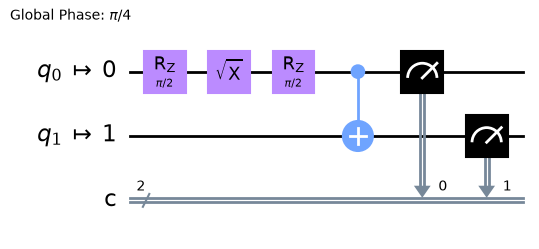

↑ the Bell circuit in fake_athens's native gates {'rz': 2, 'measure': 2, 'sx': 1, 'cx': 1}, depth 5: H became rz·sx·rz, the CX stayed native; the device's errors are attached to exactly these instructions on these physical qubits

Bell state with fake_athens noise:
  Counts: {'10': 77, '00': 2022, '11': 1934, '01': 63}
  Fidelity: 0.9658


In [19]:
print(FAKE_AVAILABLE)
if FAKE_AVAILABLE:
    # Use a fake backend (5 qubit) as an example
    fake_backend = get_fake_backend(min_qubits=5)          # the smallest snapshot with >= 5 qubits (first in alphabetical order among the 5-qubit ones)

    print(f"Fake Backend: {fake_backend.name}")
    print(f"  Qubit: {fake_backend.num_qubits}")

    # Extract noise model
    fake_noise = NoiseModel.from_backend(fake_backend)     # calibration -> NoiseModel (qubit-specific gate errors, T1/T2, readout)
    print(f"  Basis gates: {fake_noise.basis_gates}")

    # Test Bell state with fake noise
    sim_fake = AerSimulator(noise_model=fake_noise)
    sampler_fake = SamplerV2()
    sampler_fake._backend = sim_fake

    # Transpile the backend
    pm = generate_preset_pass_manager(optimization_level=1, backend=fake_backend)   # rewrite the Bell circuit in the device's gates, on its qubits
    bell_transpiled = pm.run(qc_bell)
    display(draw(bell_transpiled, idle_wires=False)); print(f"↑ the Bell circuit in {fake_backend.name}'s native gates {dict(bell_transpiled.count_ops())}, depth {bell_transpiled.depth()}: H became rz·sx·rz, the CX stayed native; the device's errors are attached to exactly these instructions on these physical qubits")

    job = sampler_fake.run([bell_transpiled], shots=4096)
    counts_fake = job.result()[0].data.c.get_counts()

    print(f"\nBell state with {fake_backend.name} noise:")
    print(f"  Counts: {counts_fake}")

    correct = counts_fake.get('00', 0) + counts_fake.get('11', 0)
    fidelity = correct / sum(counts_fake.values())
    print(f"  Fidelity: {fidelity:.4f}")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `fake_noise = NoiseModel.from_backend(fake_backend)` | the device snapshot's calibration as a noise model; `basis_gates` shows the IBM native set (`rz`, `sx`, `x`, `cx`, …) |
| `generate_preset_pass_manager(optimization_level=1, backend=fake_backend)` | transpile to the device: H → `rz·sx·rz`, qubits placed on physical qubits of the chip (hence `idle_wires=False` in the drawing) |
| `sampler_fake._backend = sim_fake` + `.run([bell_transpiled])` | simulate the transpiled circuit with the device's noise — this is how one predicts a real run before paying for it |
| Fidelity ≈ 0.96–0.97 | comparable to our hand-made model: a 5-qubit IBM device of that generation had ~1 % CX error and ~2 % readout error |

</details>


<a id='grover'></a>
## 9. Case Study: Grover's Algorithm

Let's analyse how noise affects Grover's algorithm.

Grover (3 qubits, target='101'):
  Depth: 18
  Gate: 38
  Operations: {'x': 16, 'h': 15, 'barrier': 5, 'ccz': 4, 'measure': 3}


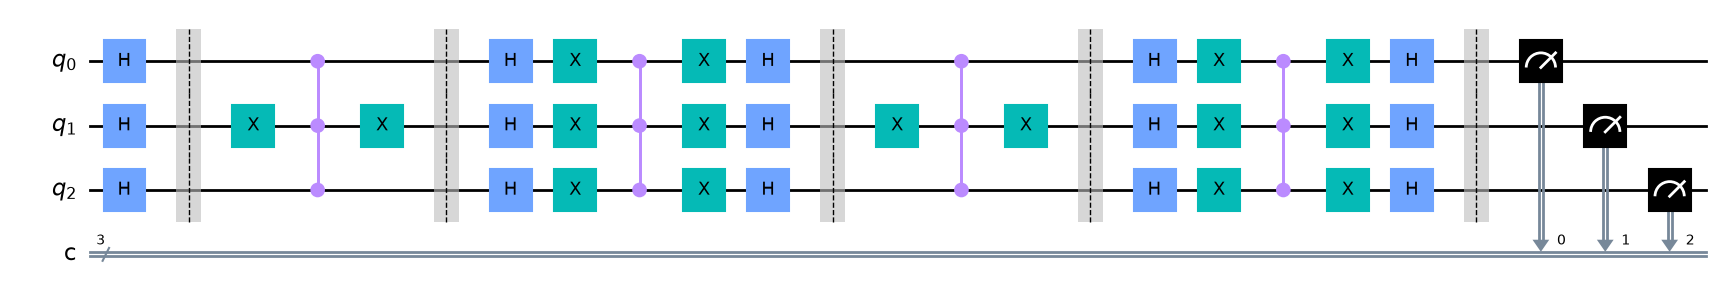

↑ Grover for '101' on 3 qubits: H layer, then 2 iterations of [oracle = X on qubit 1 · CCZ · X] + [diffuser = H X CCZ X H], then the measurement; each CCZ is unrolled by the simulator into ~6 CX gates, which is where the 2-qubit noise bites


In [20]:
def grover_circuit(n_qubits: int, marked_state: str) -> QuantumCircuit:
    """
    Build a Grover circuit that searches for a marked state.
    """
    qc = QuantumCircuit(n_qubits, n_qubits)

    # Optimal number of iterations
    n_iterations = int(np.pi / 4 * np.sqrt(2**n_qubits))   # floor(π/4 · √N): 2 for n = 3 (N = 8)

    # Initial superposition
    qc.h(range(n_qubits))                  # H on every qubit: uniform superposition
    qc.barrier()                           # visual separator (no effect on the state)

    for _ in range(n_iterations):
        # Oracle: flips the phase of the marked state
        for i, bit in enumerate(reversed(marked_state)):   # reversed: bit 0 of the string is the LAST character (Qiskit's little-endian order)
            if bit == '0':
                qc.x(i)                    # X around the multi-controlled Z turns "control on 1" into "control on 0"

        # Multi-controlled Z
        if n_qubits == 2:
            qc.cz(0, 1)
        elif n_qubits == 3:
            qc.ccz(0, 1, 2)                # phase flip of |111> only — with the X's above, of the marked state
        else:
            qc.h(n_qubits - 1)
            qc.mcx(list(range(n_qubits - 1)), n_qubits - 1)   # H·MCX·H on the last qubit = multi-controlled Z
            qc.h(n_qubits - 1)

        for i, bit in enumerate(reversed(marked_state)):
            if bit == '0':
                qc.x(i)                    # undo the X's

        qc.barrier()

        # Diffuser
        qc.h(range(n_qubits))              # diffuser = H X (multi-controlled Z) X H: reflection about the uniform superposition
        qc.x(range(n_qubits))

        if n_qubits == 2:
            qc.cz(0, 1)
        elif n_qubits == 3:
            qc.ccz(0, 1, 2)
        else:
            qc.h(n_qubits - 1)
            qc.mcx(list(range(n_qubits - 1)), n_qubits - 1)
            qc.h(n_qubits - 1)

        qc.x(range(n_qubits))
        qc.h(range(n_qubits))
        qc.barrier()

    qc.measure(range(n_qubits), range(n_qubits))

    return qc

# Grover for 3 qubits, searching for '101'
grover_3q = grover_circuit(3, '101')
print(f"Grover (3 qubits, target='101'):")
print(f"  Depth: {grover_3q.depth()}")
print(f"  Gate: {grover_3q.size()}")      # size(): number of instructions (barriers included)
print(f"  Operations: {dict(grover_3q.count_ops())}")
display(draw(grover_3q)); print("↑ Grover for '101' on 3 qubits: H layer, then 2 iterations of [oracle = X on qubit 1 · CCZ · X] + [diffuser = H X CCZ X H], then the measurement; each CCZ is unrolled by the simulator into ~6 CX gates, which is where the 2-qubit noise bites")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `n_iterations = int(np.pi / 4 * np.sqrt(2**n_qubits))` | the optimal Grover count ⌊π/4·√N⌋ = 2 for N = 8 (box below) |
| `for i, bit in enumerate(reversed(marked_state))` | Qiskit orders bits little-endian: the last character of `'101'` is qubit 0, so the string is reversed before pairing characters with qubit indices |
| `qc.x(i)` … `qc.ccz(0, 1, 2)` … `qc.x(i)` | the oracle: X gates convert the '0' bits so that the CCZ (phase flip of \|111⟩) flips the phase of the marked state only |
| `qc.h(range(n))`, `qc.x(range(n))`, CCZ, `qc.x`, `qc.h` | the diffuser (inversion about the mean) written as H X CCZ X H |
| `grover_3q.depth()`, `.size()`, `.count_ops()` | 18 layers and 38 instructions in the high-level gate set; after unrolling the 4 CCZ gates the noisy simulator sees ~24 CX |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**Optimal number of iterations and the ideal success probability.** With $N=2^3=8$ states and one marked state, $\sin\theta = 1/\sqrt N$, i.e. $\theta=\arcsin(1/\sqrt8)=0.3614$ rad. After $k$ iterations the amplitude of the marked state is $\sin\big((2k+1)\theta\big)$, so

$$k_{\rm opt}=\Big\lfloor\frac{\pi}{4}\sqrt8\Big\rfloor=\lfloor2.22\rfloor=2,\qquad
P_{\rm success}=\sin^2(5\theta)=\sin^2(1.807)=0.9453.$$

(One iteration would give $\sin^2(3\theta)=0.781$, three would overshoot to $\sin^2(7\theta)=0.330$.) The ideal entry (noise 0.000) of the next cell's table should therefore read ≈ 0.945 ± 0.004.

</details>


In [21]:
# Grover comparison: ideal vs different noise levels
def analyze_grover_noise(circuit: QuantumCircuit, target: str,
                         noise_levels: List[float]) -> dict:
    """
    Analyse Grover with different noise levels.
    """
    results = {'noise': [], 'success_prob': [], 'fidelity': []}   # 'fidelity' stays empty: the author only fills the first two lists

    for p in noise_levels:
        if p == 0:
            # Ideal
            sim = AerSimulator()
        else:
            noise = create_realistic_noise_model(          # scale every error with the 2-qubit error p:
                t1=100e3, t2=80e3,
                p_depol_1q=p/10, p_depol_2q=p,             #   1q error = p/10
                p_readout_0=p/2, p_readout_1=p             #   readout: P(1|0) = p/2, P(0|1) = p
            )
            sim = AerSimulator(noise_model=noise)

        sampler = SamplerV2()
        if p > 0:
            sampler._backend = sim                         # noisy simulator only when p > 0 (the default SamplerV2 is ideal)

        job = sampler.run([circuit], shots=4096)           # Aer unrolls the ccz gates into the model's basis (cx, h, ...) before applying the errors
        counts = job.result()[0].data.c.get_counts()

        total = sum(counts.values())
        success = counts.get(target, 0) / total            # probability of reading the marked bitstring

        results['noise'].append(p)
        results['success_prob'].append(success)

    return results

# Analysis
noise_levels = [0, 0.001, 0.005, 0.01, 0.02, 0.05, 0.1]
grover_results = analyze_grover_noise(grover_3q, '101', noise_levels)

print("Grover (3 qubits): Success vs Noise")
print("=" * 40)
print(f"{'Noise (2q)':<15} {'P(success)':<15}")
print("-" * 30)
for p, s in zip(grover_results['noise'], grover_results['success_prob']):
    print(f"{p:<15.3f} {s:<15.4f}")


Grover (3 qubits): Success vs Noise
Noise (2q)      P(success)     
------------------------------
0.000           0.9419         
0.001           0.9297         
0.005           0.9211         
0.010           0.8928         
0.020           0.8611         
0.050           0.7444         
0.100           0.6160         


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `create_realistic_noise_model(p_depol_1q=p/10, p_depol_2q=p, p_readout_0=p/2, p_readout_1=p)` | one knob `p` scales all errors together, keeping the realistic ratios (2q gate : readout : 1q gate = 1 : 1 : 0.1) |
| `if p > 0: sampler._backend = sim` | the p = 0 row is the ideal reference (≈ 0.945 from the previous box) |
| `sampler.run([circuit])` with `ccz` gates | the noise model's `basis_gates` contain no `ccz`, so Aer unrolls each CCZ into CX + 1-qubit gates and applies the errors to those — the 4 CCZ cost ≈ 24 noisy CX |
| `success = counts.get(target, 0) / total` | P(success) = fraction of shots reading `'101'`; the random-guess floor is 1/8 |
| the table | P(success) falls from ≈ 0.945 to ≈ 0.6 at p = 0.1 — the box below splits the loss between readout and gates |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**Where does the success probability go?** Take the last row, $p=0.1$ (2-qubit error 10 %, readout $P(1|0)=5\,\%$, $P(0|1)=10\,\%$, 1-qubit error 1 %).

- Readout alone: the three bits of `101` must all be read correctly, $P=(1-0.1)\,(1-0.05)\,(1-0.1)=0.7695$, so even perfect gates would give $0.945\times0.7695=0.727$.
- Gates: the ≈ 24 CX of the unrolled circuit each cost up to $p/2$ in the worst case, plus ~45 one-qubit gates at $p/10$; the survival of the "right" answer is roughly $0.727\times(1-p/2)^{24}\times\ldots$, but a depolarised Grover state is not simply "wrong" — with probability 1/8 it still reads `101` — so the loss is milder than the crude product: the cell prints ≈ 0.6.

Rule of thumb from the table: with today's ~1 % two-qubit errors ($p=0.01$) a 3-qubit Grover keeps ≈ 0.89 of its success probability; at $p=0.05$ it keeps ≈ 0.75. Exercise 2 of the author asks where it crosses 50 % for 4 qubits (more CCZ → more CX).

</details>


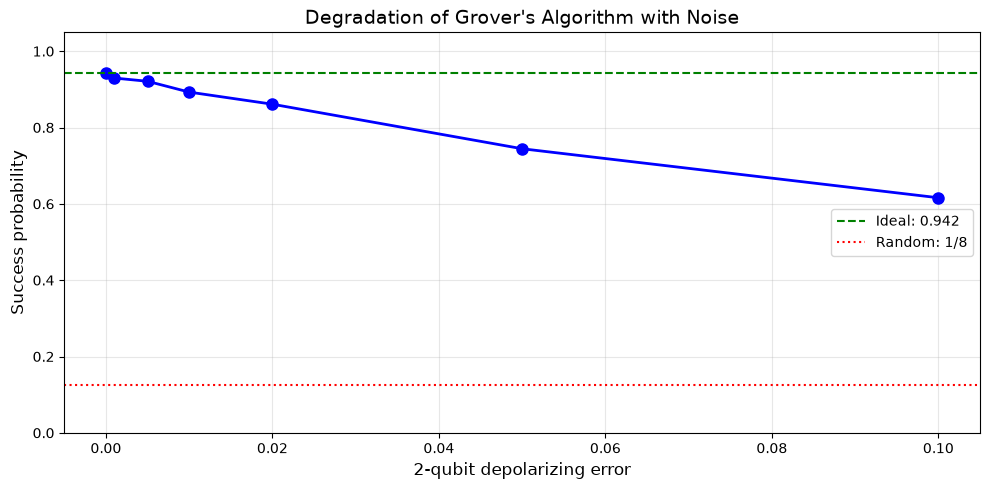

↑ Grover's success probability vs the 2-qubit error p (readout and 1-qubit errors scaled with it): from the ideal 0.945 (green) down towards the 1/8 random floor (red)


In [22]:
# Plot
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(grover_results['noise'], grover_results['success_prob'],
        'bo-', linewidth=2, markersize=8)

# Reference line for the ideal case
ax.axhline(y=grover_results['success_prob'][0], color='g', linestyle='--',     # [0] = the p = 0 (ideal) entry
           label=f'Ideal: {grover_results["success_prob"][0]:.3f}')

# Random threshold
ax.axhline(y=1/8, color='r', linestyle=':', label='Random: 1/8')              # guessing one of 8 states

ax.set_xlabel('2-qubit depolarizing error', fontsize=12)
ax.set_ylabel('Success probability', fontsize=12)
ax.set_title('Degradation of Grover\'s Algorithm with Noise', fontsize=14)
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_ylim(0, 1.05)

plt.tight_layout()
plt.show()
print("↑ Grover's success probability vs the 2-qubit error p (readout and 1-qubit errors scaled with it): from the ideal 0.945 (green) down towards the 1/8 random floor (red)")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `grover_results['success_prob'][0]` | the ideal value (first entry, p = 0) drawn as the green reference line |
| `ax.axhline(y=1/8, ...)` | the random-guess floor: 1 marked state out of 8 |

</details>


<a id='exercises'></a>
## 10. Exercises

### Exercise 1: Comparing Errors (Easy)
Create noise models with only gate errors, only readout errors, and both combined. Compare their effect on a Bell state.

### Exercise 2: Noise Threshold (Medium)
For the 4-qubit Grover algorithm, find the noise threshold beyond which the success probability falls below 50%.

### Exercise 3: T1 vs T2 (Advanced)
Study separately the effect of T1 and T2 on a superposition |+>. Which parameter is more critical?

In [23]:
# Space for the exercises

# Ex 1: Comparing errors
# noise_gate_only = NoiseModel()
# noise_readout_only = NoiseModel()
# ...

# Ex 2: Grover threshold
# grover_4q = grover_circuit(4, '1010')
# ...


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `# Ex 1 ... # Ex 2 ...` | the author's empty workspace for the three exercises above; the hints name the objects to start from (`NoiseModel()`, `grover_circuit(4, '1010')`) |
| Exercise 3 (T1 vs T2) | solved as task (3) of the 🔬 section below — try it yourself first |

</details>


<a id='indepth'></a>
## 🔬 In-depth analysis

1. **Seeing the invisible errors.** Section 2 showed that bit flip, phase flip and depolarising noise on $|+\rangle$ all give 50/50 in the $Z$ basis. Write `simulate_error_effect_x(error)` — the same circuit with an **H before the measurement** ($X$-basis measurement) — and run the three errors with $p=0.1$ again (10 000 shots). Predict first: the fraction of `'1'` outcomes should be 0 % (bit flip), 10 % (phase flip) and 5 % (depolarising, $p/2$).
2. **Readout-error mitigation.** Under `realistic_noise`, measure the 1-qubit confusion matrix $M$ with two calibration circuits ($|0\rangle$ and $|1\rangle$, 10 000 shots), build $M_2 = M\otimes M$ (`np.kron`) and use it to correct the noisy Bell counts of `compare_ideal_noisy(qc_bell, realistic_noise)`: solve $\vec p_{\rm meas} = M_2^{\!\top}\vec p_{\rm true}$ for $\vec p_{\rm true}$ (`np.linalg.solve`, bitstring order `00, 01, 10, 11`). Print the raw and the mitigated Bell fidelity: the mitigated one should be close to the $1-p/2 \approx 0.997$ left by the CX error alone.
3. **The author's Exercise 3 — $T_1$ vs $T_2$ on $|+\rangle$.** Use a Ramsey-type circuit H · (100 × `id`, 50 ns each) · H · measure, with the thermal error attached to `id` only, and compare two models with the same time constant $T = 10\,\mu$s: *T1-only* (`t1 = T, t2 = 2T`: no pure dephasing) and *T2-only* (`t1 = 1e12`, `t2 = T`). Show that $P(0) = \tfrac12\big(1+e^{-t/T_2}\big)$ in both cases (0.889 vs 0.803 for $t=5\,\mu$s) — which parameter is more critical for a superposition?

Write your code in the empty cell below; a reference solution follows it. Try first, then compare.


In [24]:
# 🔬 In-depth analysis — your code here



In [25]:
# Reference solution
# (1) X-basis measurement reveals the errors that the Z basis cannot see
def simulate_error_effect_x(error, n_shots: int = 10000) -> dict:
    qc = QuantumCircuit(1, 1)
    qc.h(0)                                                    # |+>
    qc.id(0)                                                   # a 'wait' instruction that carries the error (so the two H gates stay perfect)
    qc.h(0)                                                    # second H = measure in the X basis (|+> -> '0', |-> -> '1')
    qc.measure(0, 0)
    noise = NoiseModel()
    noise.add_all_qubit_quantum_error(error, ['id'])           # attaching it to 'h' would apply the error twice (after both H gates)
    sampler = SamplerV2(); sampler._backend = AerSimulator(noise_model=noise)
    return sampler.run([qc], shots=n_shots).result()[0].data.c.get_counts()

for name, err in [('bit flip', bit_flip), ('phase flip', phase_flip), ('depolarizing', depol)]:
    c = simulate_error_effect_x(err)
    print(f"(1) {name:<13} X-basis counts {c}  ->  P('1') = {c.get('1', 0) / 10000:.3f}")   # expected 0.000 / 0.100 / 0.050

# (2) readout-error mitigation with the measured confusion matrix
def measured_counts(qc, shots=10000):                          # noisy counts under realistic_noise (only the second element of the pair)
    return compare_ideal_noisy(qc, realistic_noise, shots=shots)[1]

M = np.zeros((2, 2))                                           # M[i, j] = P(read j | prepared i)
for i in (0, 1):
    cal = QuantumCircuit(1, 1)
    if i == 1: cal.x(0)                                        # prepare |1> (the X carries a tiny gate error, negligible here)
    cal.measure(0, 0)
    c = measured_counts(cal)
    M[i] = [c.get('0', 0) / 10000, c.get('1', 0) / 10000]
print(f"(2) measured confusion matrix M (rows = true state):\n{np.round(M, 4)}")

M2 = np.kron(M, M)                                             # 2-qubit matrix for independent readout errors, index = 2*bit1 + bit0
raw = measured_counts(qc_bell)
keys = ['00', '01', '10', '11']
p_meas = np.array([raw.get(k, 0) for k in keys]) / sum(raw.values())   # measured probabilities in the order 00, 01, 10, 11
p_true = np.linalg.solve(M2.T, p_meas)                        # p_meas = M2^T p_true  ->  p_true
print(f"(2) Bell fidelity raw = {p_meas[0] + p_meas[3]:.4f}, mitigated = {p_true[0] + p_true[3]:.4f}  (CX error alone: 1 - p/2 = {1 - 0.005/2:.4f})")

# (3) T1 vs T2 on |+> (Exercise 3 of the author)
def ramsey_p0(t1, t2, n_idle=100, dt=50, shots=4096):
    qc = QuantumCircuit(1, 1)
    qc.h(0)
    for _ in range(n_idle): qc.id(0)                           # wait n_idle × dt ns
    qc.h(0)
    qc.measure(0, 0)
    noise = NoiseModel()
    noise.add_all_qubit_quantum_error(thermal_relaxation_error(t1, t2, dt), ['id'])   # error on the waits only
    sampler = SamplerV2(); sampler._backend = AerSimulator(noise_model=noise)
    c = sampler.run([qc], shots=shots).result()[0].data.c.get_counts()
    return c.get('0', 0) / shots

T = 10e3                                                       # 10 µs; the circuit waits t = 100 × 50 ns = 5 µs
t = 100 * 50
p0_t1_only = ramsey_p0(t1=T, t2=2 * T)                         # T1 only: T2 takes its maximum value 2·T1 (no pure dephasing)
p0_t2_only = ramsey_p0(t1=1e12, t2=T)                          # T2 only: T1 effectively infinite
print(f"(3) T1-only (T1 = 10 us, T2 = 20 us): P(0) = {p0_t1_only:.3f}   theory (1 + exp(-t/T2))/2 = {(1 + np.exp(-t / (2 * T))) / 2:.3f}")
print(f"(3) T2-only (T2 = 10 us):             P(0) = {p0_t2_only:.3f}   theory (1 + exp(-t/T2))/2 = {(1 + np.exp(-t / T)) / 2:.3f}")
print("(3) a superposition only feels T2: the same time constant hurts twice as much as dephasing time than as relaxation time")


(1) bit flip      X-basis counts {'0': 10000}  ->  P('1') = 0.000
(1) phase flip    X-basis counts {'0': 9032, '1': 968}  ->  P('1') = 0.097
(1) depolarizing  X-basis counts {'0': 9496, '1': 504}  ->  P('1') = 0.050


(2) measured confusion matrix M (rows = true state):
[[0.9829 0.0171]
 [0.0423 0.9577]]
(2) Bell fidelity raw = 0.9427, mitigated = 1.0000  (CX error alone: 1 - p/2 = 0.9975)
(3) T1-only (T1 = 10 us, T2 = 20 us): P(0) = 0.889   theory (1 + exp(-t/T2))/2 = 0.889
(3) T2-only (T2 = 10 us):             P(0) = 0.806   theory (1 + exp(-t/T2))/2 = 0.803
(3) a superposition only feels T2: the same time constant hurts twice as much as dephasing time than as relaxation time


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| (1) `qc.h(0); qc.id(0); qc.h(0)` with the error on `'id'` | the error channel sits between state preparation and the X-basis measurement; attaching it to `'h'` would apply it twice (after both H gates) |
| (1) P('1') ≈ 0.000 / 0.100 / 0.050 | bit flip: \|+⟩ is an eigenstate of X; phase flip: \|+⟩ → \|−⟩ with probability p; depolarising: I/2 reads '1' half of the time, p/2 in total |
| (2) `M[i] = [P(read 0), P(read 1)]` from two calibration circuits | the confusion matrix measured the way a real device calibrates it; `np.kron(M, M)` assumes independent readout errors on the two qubits |
| (2) `np.linalg.solve(M2.T, p_meas)` | inverts p_meas = M2ᵀ·p_true; the mitigated fidelity recovers ≈ 0.99, i.e. the readout contribution (≈ 5 %) is removed and only the CX error (0.25 % + 300 ns of decay) remains — the mitigated probabilities may be slightly negative/above 1 because of shot noise |
| (3) `ramsey_p0(t1, t2)` | H · wait · H · measure reads the coherence: P(0) = ½(1 + Re ρ₀₁·2) = ½(1 + e^(−t/T₂)); with T1-only the coherence still decays with T₂ = 2T₁ (0.889), with pure dephasing T₂ = T gives 0.803 — T₂ is the critical parameter for superpositions |

</details>


## References

1. **Nielsen & Chuang** (2000). *Quantum Computation and Quantum Information*. Chapter 8: Quantum Noise.

2. **Preskill** (1998). *Lecture Notes on Quantum Computation*. Chapter 3: Quantum Noise.

3. [Qiskit Aer Documentation](https://qiskit.github.io/qiskit-aer/)

4. [IBM Quantum Documentation - Errors](https://docs.quantum.ibm.com/)

---

**Course**: Quantum Computing Laboratory  
**Version**: 2.2.0  
**License**: MIT